# Data loading

In [9]:
from pathlib import Path
import re
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.transform import from_origin
from pyresample import geometry, kd_tree
import matplotlib.pyplot as plt

DATA = Path("../data")
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)

STRIPS = ["M3G20090205T111013", "M3G20090205T092400"]   # primary strip first

# Apollo 15 landing site and subset box (degrees)
SITE_LAT, SITE_LON = 26.132, 3.634
LAT_MIN, LAT_MAX = 25.4, 26.9
LON_MIN, LON_MAX = 2.8, 4.05     # tightened to what the primary strip fully covers
RES = 0.0045                     # output grid, ~140 m/pixel

def find(strip, kind, ext="img"):
    """Locate e.g. the RFL .IMG for a strip anywhere under data/."""
    hits = [p for p in DATA.rglob(f"{strip}_*_{kind}.*")
            if p.suffix.lower() == f".{ext}"]
    if not hits:
        raise FileNotFoundError(f"{strip} {kind}.{ext} not found in {DATA}")
    return hits[0]

In [10]:
for strip in STRIPS:
    print(strip)
    for kind in ["RFL", "SUP", "LOC", "OBS"]:
        with rasterio.open(find(strip, kind)) as src:
            print(f"  {kind}: bands={src.count:3d}  lines={src.height}  "
                  f"samples={src.width}  dtype={src.dtypes[0]}")

M3G20090205T111013
  RFL: bands= 85  lines=13822  samples=304  dtype=float32
  SUP: bands=  3  lines=13822  samples=304  dtype=float32
  LOC: bands=  3  lines=13822  samples=304  dtype=float64
  OBS: bands= 10  lines=13822  samples=304  dtype=float32
M3G20090205T092400
  RFL: bands= 85  lines=13197  samples=304  dtype=float32
  SUP: bands=  3  lines=13197  samples=304  dtype=float32
  LOC: bands=  3  lines=13197  samples=304  dtype=float64
  OBS: bands= 10  lines=13197  samples=304  dtype=float32


/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [11]:
def read_wavelengths(strip):
    text = find(strip, "RFL", ext="hdr").read_text()
    m = re.search(r"wavelength\s*=\s*\{([^}]*)\}", text, re.I)
    return np.array([float(v) for v in m.group(1).split(",")])

wl = read_wavelengths(STRIPS[0])
print(len(wl), "bands:", wl[0], "to", wl[-1])

85 bands: 460.99 to 2976.2


# Subset image to Mons Hadley

In [12]:
def load_subset(strip):
    with rasterio.open(find(strip, "LOC")) as src:
        lon, lat = src.read(1), src.read(2)
    lon = ((lon + 180) % 360) - 180                 # force -180..180

    in_box = (lat > LAT_MIN) & (lat < LAT_MAX) & (lon > LON_MIN) & (lon < LON_MAX)
    rows = np.where(in_box.any(axis=1))[0]
    if rows.size == 0:
        print(f"{strip}: does not cross the box")
        return None
    r0, r1 = rows.min(), rows.max() + 1
    win = Window(0, r0, lon.shape[1], r1 - r0)       # col_off, row_off, width, height

    with rasterio.open(find(strip, "RFL")) as src:
        rfl = src.read(window=win)                   # (85, lines, 304)
    with rasterio.open(find(strip, "OBS")) as src:
        obs = src.read(window=win)                   # (10, lines, 304)
    rfl = np.where(rfl < -900, np.nan, rfl)          # -999 = no data

    lon, lat = lon[r0:r1], lat[r0:r1]
    d_km = np.hypot(lat - SITE_LAT,
                    (lon - SITE_LON) * np.cos(np.radians(SITE_LAT))).min() * 30.3
    print(f"{strip}: lines {r0}-{r1}, rfl {rfl.shape}, "
          f"nearest pixel to landing site = {d_km:.2f} km")
    return dict(strip=strip, lon=lon, lat=lat, rfl=rfl, obs=obs)

subsets = [s for s in (load_subset(s) for s in STRIPS) if s is not None]

M3G20090205T111013: lines 12274-12571, rfl (85, 297, 304), nearest pixel to landing site = 0.03 km
M3G20090205T092400: lines 5294-5591, rfl (85, 297, 304), nearest pixel to landing site = 0.04 km


# Georeferencing (Save files)

In [13]:
MOON = {"proj": "longlat", "R": 1737400, "no_defs": True}
WIDTH  = int(round((LON_MAX - LON_MIN) / RES))
HEIGHT = int(round((LAT_MAX - LAT_MIN) / RES))
AREA = geometry.AreaDefinition("a15", "", "", MOON, WIDTH, HEIGHT,
                               (LON_MIN, LAT_MIN, LON_MAX, LAT_MAX))

# pyresample measures search distances on an Earth-sized sphere,
# so scale the lunar radius up by R_earth / R_moon (~3.67)
EARTH_R, MOON_R = 6370997.0, 1737400.0
RADIUS = 200 * EARTH_R / MOON_R      # 200 m on the Moon

def georeference(sub, key="rfl"):
    swath = geometry.SwathDefinition(lons=sub["lon"], lats=sub["lat"])
    data = np.moveaxis(sub[key], 0, -1)              # (lines, samples, bands)
    out = kd_tree.resample_nearest(swath, data, AREA,
                                   radius_of_influence=RADIUS, fill_value=np.nan)
    return np.moveaxis(out, -1, 0).astype("float32") # (bands, HEIGHT, WIDTH)

def save_geotiff(cube, path):
    with rasterio.open(path, "w", driver="GTiff", width=WIDTH, height=HEIGHT,
                       count=cube.shape[0], dtype="float32", nodata=np.nan,
                       crs="+proj=longlat +R=1737400 +no_defs",
                       transform=from_origin(LON_MIN, LAT_MAX, RES, RES)) as dst:
        dst.write(cube)

for sub in subsets:
    sub["rfl_geo"] = georeference(sub, "rfl")
    save_geotiff(sub["rfl_geo"], OUT / f"{sub['strip']}_a15_rfl.tif")
    print(sub["strip"], sub["rfl_geo"].shape)

M3G20090205T111013 (85, 333, 278)
M3G20090205T092400 (85, 333, 278)


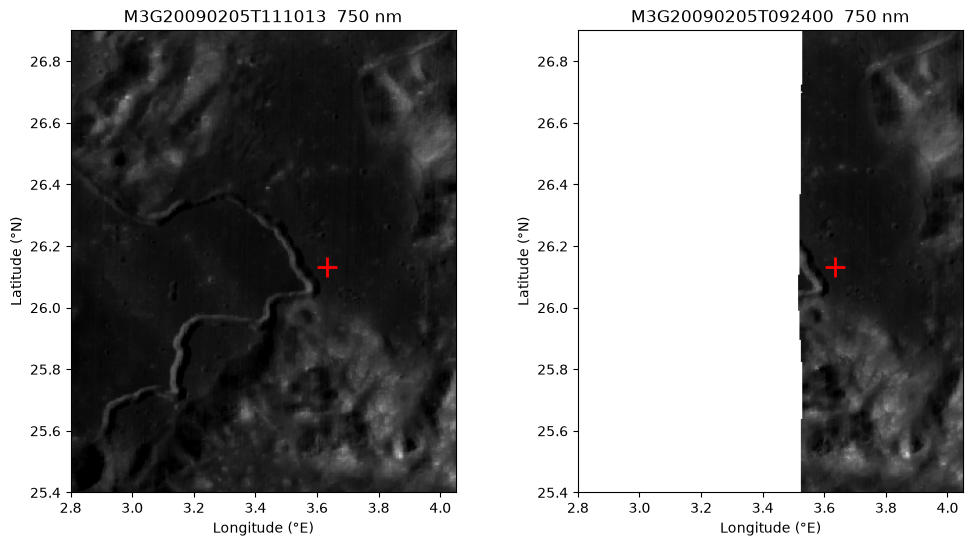

In [14]:
b = np.argmin(np.abs(wl - 750))                      # ~750 nm band
fig, axes = plt.subplots(1, len(subsets), figsize=(6 * len(subsets), 6), squeeze=False)
for ax, sub in zip(axes[0], subsets):
    ax.imshow(sub["rfl_geo"][b], cmap="gray",
              extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX), vmin=0.03, vmax=0.20)
    ax.plot(SITE_LON, SITE_LAT, "r+", ms=14, mew=2)
    ax.set_title(f"{sub['strip']}  {wl[b]:.0f} nm")
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
plt.show()

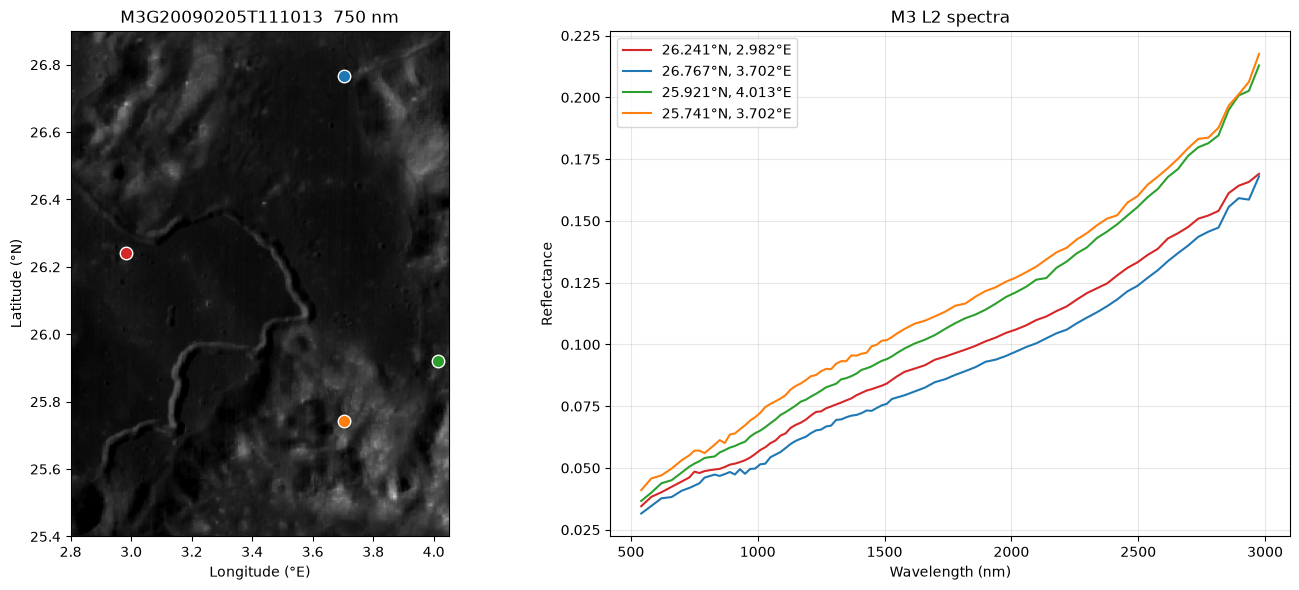

In [16]:
cube = subsets[0]["rfl_geo"]                         # (bands, HEIGHT, WIDTH), primary strip
valid = np.isfinite(cube[b]) & (cube[b] > 0)
rng = np.random.default_rng(42)                      # change or remove the seed for new points
rows, cols = np.where(valid)
pick = rng.choice(rows.size, size=4, replace=False)
rows, cols = rows[pick], cols[pick]
lons = LON_MIN + (cols + 0.5) * RES
lats = LAT_MAX - (rows + 0.5) * RES

colors = ["tab:red", "tab:blue", "tab:green", "tab:orange"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.imshow(cube[b], cmap="gray", vmin=0.03, vmax=0.20,
           extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax1.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
for i in range(4):
    ax1.plot(lons[i], lats[i], "o", color=colors[i], ms=9, mec="white")
ax1.set_xlabel("Longitude (°E)"); ax1.set_ylabel("Latitude (°N)")
ax1.set_title(f"{subsets[0]['strip']}  {wl[b]:.0f} nm")

for i in range(4):
    ax2.plot(wl, cube[:, rows[i], cols[i]], color=colors[i],
             label=f"{lats[i]:.3f}°N, {lons[i]:.3f}°E")
ax2.set_xlabel("Wavelength (nm)"); ax2.set_ylabel("Reflectance")
ax2.set_title("M3 L2 spectra")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [17]:
empty = np.where(np.isnan(cube).all(axis=(1, 2)))[0]
print("All-NaN bands:", empty, "→ wavelengths:", wl[empty])

All-NaN bands: [0 1] → wavelengths: [460.99 500.92]


# Data Cleaning

In [18]:
cube = subsets[0]["rfl_geo"]
footprint = np.isfinite(cube[b])                     # pixels inside the strip
n = footprint.sum()

print(f"{'band':>4} {'wl(nm)':>8} {'NaN%':>7} {'<=0 %':>7} {'>1 %':>6} {'min':>8} {'max':>8}")
for i in range(cube.shape[0]):
    v = cube[i][footprint]
    nan = np.isnan(v).mean() * 100
    f = v[np.isfinite(v)]
    if f.size == 0:
        print(f"{i:4d} {wl[i]:8.1f} {nan:7.2f}   (empty band)")
        continue
    neg, hi = (f <= 0).mean() * 100, (f > 1).mean() * 100
    if nan > 0 or neg > 0 or hi > 0:                 # only print bands with a problem
        print(f"{i:4d} {wl[i]:8.1f} {nan:7.2f} {neg:7.2f} {hi:6.2f} {f.min():8.4f} {f.max():8.4f}")

band   wl(nm)    NaN%   <=0 %   >1 %      min      max
   0    461.0  100.00   (empty band)
   1    500.9  100.00   (empty band)
   3    580.8    0.00    0.02   0.00  -0.0139   0.1393


In [19]:
# 1. drop bands that are entirely empty
good = ~np.isnan(cube[:, footprint]).all(axis=1)
cube_c, wl_c = cube[good].copy(), wl[good]

# 2. set physically impossible values to NaN
cube_c[(cube_c <= 0) | (cube_c > 1)] = np.nan

# 3. mask pixels that are shadowed or have any remaining bad band
b_c = np.argmin(np.abs(wl_c - 750))
mask = footprint & np.isfinite(cube_c).all(axis=0) & (cube_c[b_c] > 0.02)

print(f"Bands kept: {cube_c.shape[0]} of {cube.shape[0]}")
print(f"Pixels kept: {mask.sum()} of {n} ({mask.sum() / n * 100:.1f}%)")

Bands kept: 83 of 85
Pixels kept: 92400 of 92574 (99.8%)


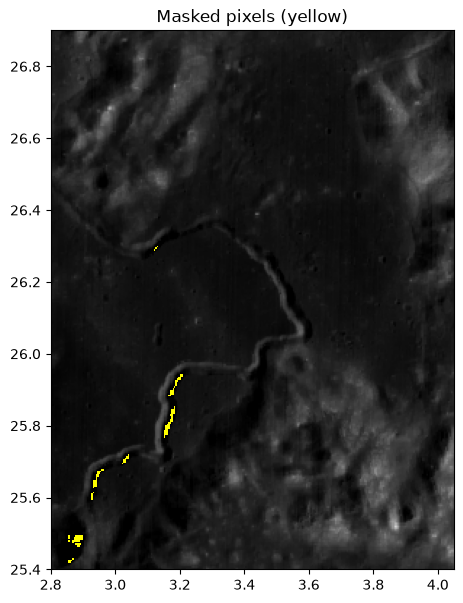

In [46]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(cube_c[b_c], cmap="gray", vmin=0.03, vmax=0.20,
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.imshow(np.where(footprint & ~mask, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1,
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX), interpolation="nearest")
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.set_title("Masked pixels (yellow)")
plt.show()

Sample columns with band-3 values <= 0: [160]


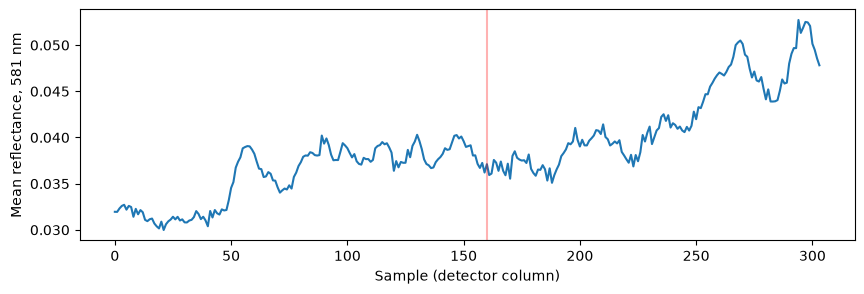

In [21]:
raw = subsets[0]["rfl"]                              # (85, lines, 304), sensor geometry
neg_cols = np.where((raw[3] <= 0).any(axis=0))[0]
print("Sample columns with band-3 values <= 0:", neg_cols)

col_mean = np.nanmean(raw[3], axis=0)                # mean of band 3 along each column
plt.figure(figsize=(10, 3))
plt.plot(col_mean)
for c in neg_cols:
    plt.axvline(c, color="r", alpha=0.3)
plt.xlabel("Sample (detector column)"); plt.ylabel("Mean reflectance, 581 nm")
plt.show()

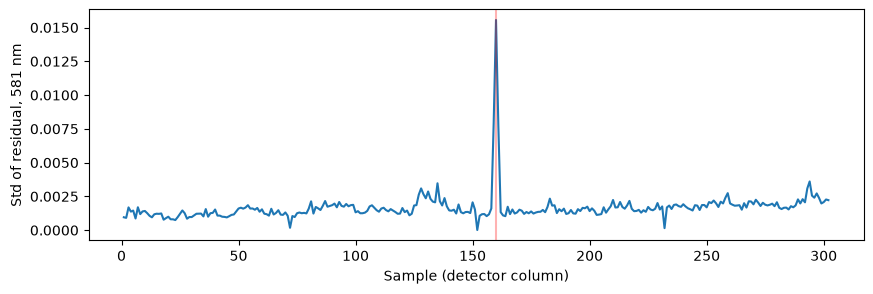

/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


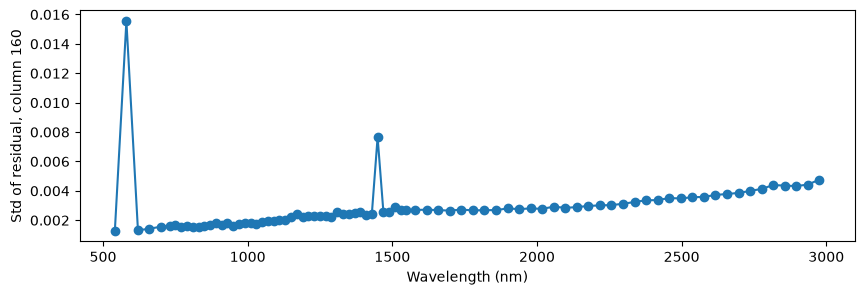

In [22]:
raw = subsets[0]["rfl"]
c = int(neg_cols[0])

# band 3: noise of every column relative to its neighbours
resid = raw[3, :, 1:-1] - 0.5 * (raw[3, :, :-2] + raw[3, :, 2:])
plt.figure(figsize=(10, 3))
plt.plot(np.arange(1, raw.shape[2] - 1), np.nanstd(resid, axis=0))
plt.axvline(c, color="r", alpha=0.3)
plt.xlabel("Sample (detector column)"); plt.ylabel("Std of residual, 581 nm")
plt.show()

# column c: same measure for every band, to see if other wavelengths are affected
resid_c = raw[:, :, c] - 0.5 * (raw[:, :, c - 1] + raw[:, :, c + 1])
plt.figure(figsize=(10, 3))
plt.plot(wl, np.nanstd(resid_c, axis=1), "o-")
plt.xlabel("Wavelength (nm)"); plt.ylabel(f"Std of residual, column {c}")
plt.show()

In [23]:
# 1. keep 620–2500 nm (drops empty bands 0–1, noisy 541/581 nm, and the thermal/3 µm end)
keep = (wl >= 620) & (wl <= 2500)
cube_c, wl_c = cube[keep].copy(), wl[keep]

# 2. set physically impossible values to NaN
cube_c[(cube_c <= 0) | (cube_c > 1)] = np.nan

# 3. mask shadowed pixels and any pixel with a remaining bad band
b_c = np.argmin(np.abs(wl_c - 750))
mask = footprint & np.isfinite(cube_c).all(axis=0) & (cube_c[b_c] > 0.02)

print(f"Bands kept: {cube_c.shape[0]} of {cube.shape[0]}  "
      f"({wl_c[0]:.0f}–{wl_c[-1]:.0f} nm)")
print(f"Pixels kept: {mask.sum()} of {n} ({mask.sum() / n * 100:.1f}%)")

Bands kept: 69 of 85  (621–2497 nm)
Pixels kept: 92422 of 92574 (99.8%)


# Input Data Prep

In [24]:
X = cube_c[:, mask].T        # (92422 pixels, 69 bands), ready for clustering or unmixing

# Clustering with Agglomerative ward clustering with KNN assistance

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, fcluster

X = cube_c[:, mask].T                                # (pixels, bands)
Xz = StandardScaler().fit_transform(X)               # column-wise z-score

conn = kneighbors_graph(Xz, n_neighbors=15, include_self=False, n_jobs=-1)

ward = AgglomerativeClustering(n_clusters=None, distance_threshold=0,
                               linkage="ward", connectivity=conn,
                               compute_full_tree=True).fit(Xz)

# build a scipy-style linkage matrix from the fitted tree
n_samples = Xz.shape[0]
counts = np.zeros(ward.children_.shape[0])
for i, (left, right) in enumerate(ward.children_):
    counts[i] = ((1 if left < n_samples else counts[left - n_samples]) +
                 (1 if right < n_samples else counts[right - n_samples]))
dist = np.maximum.accumulate(ward.distances_)        # enforce non-decreasing merges
Z = np.column_stack([ward.children_, dist, counts]).astype(float)

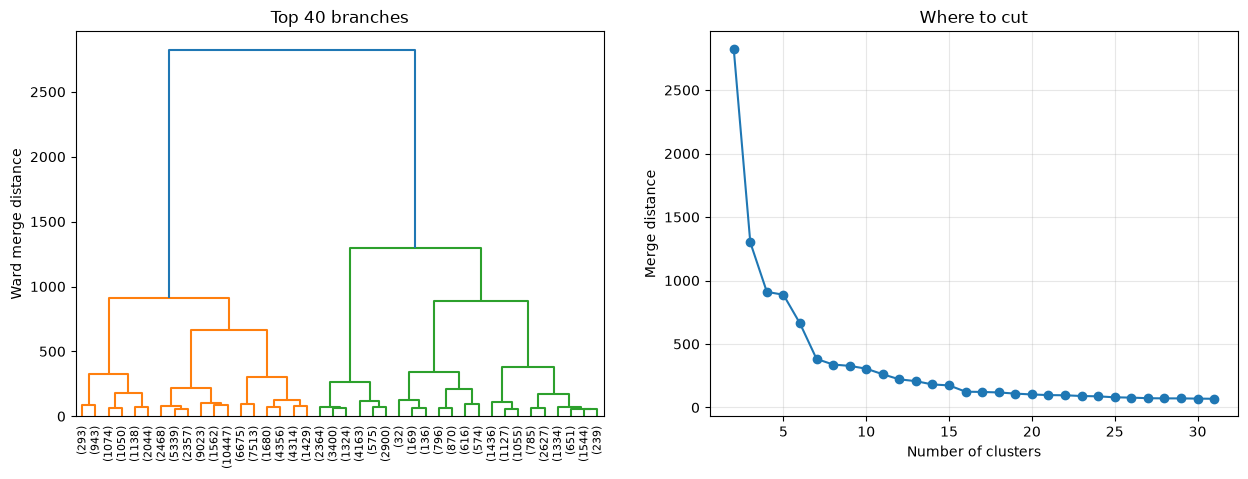

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z, truncate_mode="lastp", p=40, show_leaf_counts=True,
           leaf_rotation=90, ax=ax1)
ax1.set_ylabel("Ward merge distance"); ax1.set_title("Top 40 branches")

last = Z[-30:, 2][::-1]                              # last 30 merges, largest first
ax2.plot(np.arange(2, 32), last, "o-")
ax2.set_xlabel("Number of clusters"); ax2.set_ylabel("Merge distance")
ax2.set_title("Where to cut"); ax2.grid(alpha=0.3)
plt.show()

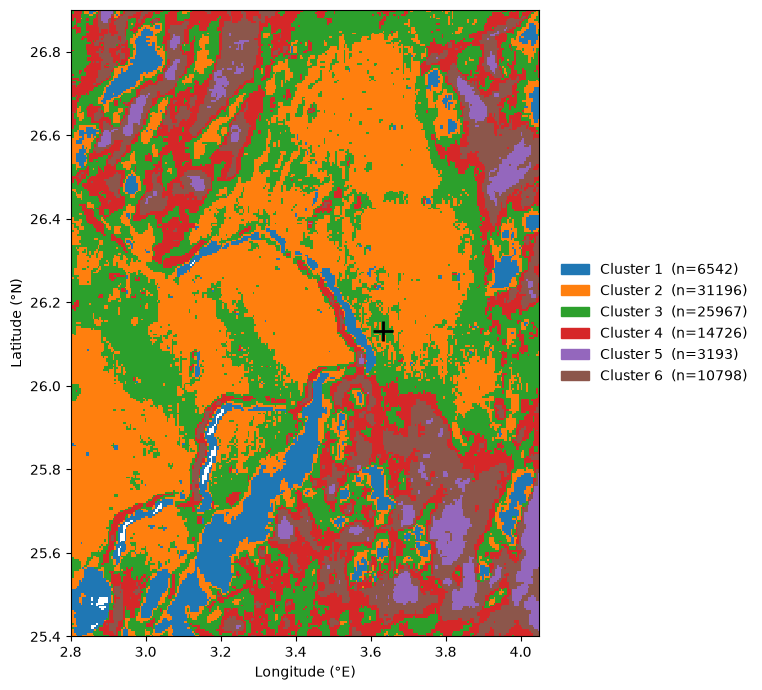

In [28]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

k = int(labels.max())
colors = plt.get_cmap("tab10").colors[:k] if k <= 10 else plt.get_cmap("tab20").colors[:k]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(0.5, k + 1.5), k)      # one bin per integer label

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(label_img, cmap=cmap, norm=norm, interpolation="nearest",
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.plot(SITE_LON, SITE_LAT, "k+", ms=14, mew=2)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")

sizes = np.bincount(labels, minlength=k + 1)[1:]
handles = [Patch(color=colors[i], label=f"Cluster {i + 1}  (n={sizes[i]})")
           for i in range(k)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout(); plt.show()

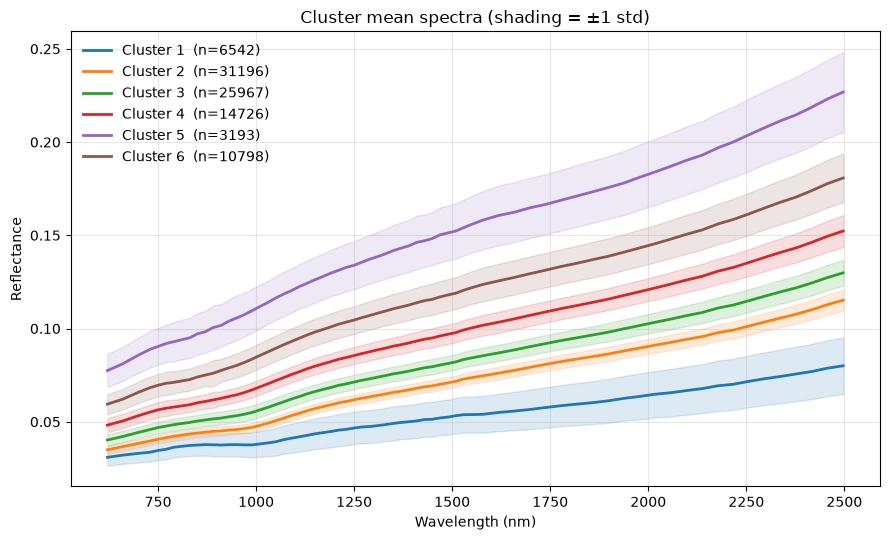

In [30]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for i in range(k):
    spec = X[labels == i + 1]                        # reflectance, not z-scores
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors[i], lw=2, label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance")
ax.set_title("Cluster mean spectra (shading = ±1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [31]:
def continuum_removed(wl, R):
    """Divide each spectrum (row of R) by its upper convex hull."""
    out = np.empty_like(R)
    for j, y in enumerate(R):
        hull = []                                    # indices of hull points
        for i in range(len(wl)):
            while len(hull) >= 2:
                i1, i2 = hull[-2], hull[-1]
                cross = ((wl[i2] - wl[i1]) * (y[i] - y[i1]) -
                         (y[i2] - y[i1]) * (wl[i] - wl[i1]))
                if cross >= 0:                       # i2 lies on or below the line i1→i
                    hull.pop()
                else:
                    break
            hull.append(i)
        out[j] = y / np.interp(wl, wl[hull], y[hull])
    return out

X_cr = continuum_removed(wl_c, X)                    # (92422 pixels, 69 bands)
print(X_cr.shape, "range:", X_cr.min().round(3), "to", X_cr.max().round(3))

(92422, 69) range: 0.395 to 1.0


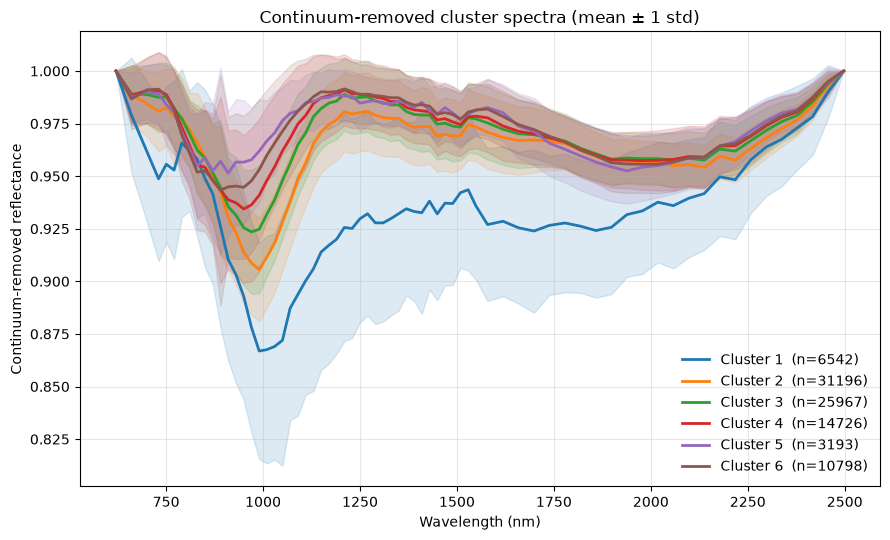

In [32]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for i in range(k):
    spec = X_cr[labels == i + 1]
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors[i], lw=2, label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Continuum-removed reflectance")
ax.set_title("Continuum-removed cluster spectra (mean ± 1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Continuum removal based clustering

In [38]:
# continuum removal pins the first and last band to exactly 1.0 for every pixel,
# so those columns have zero variance and carry no information: drop them
var_ok = X_cr.std(axis=0) > 1e-6
print("Bands dropped (zero variance):", wl_c[~var_ok])
wl_cr = wl_c[var_ok]

# centre each band but do NOT scale: deep absorption bands keep their natural weight
Xz_cr = X_cr[:, var_ok] - X_cr[:, var_ok].mean(axis=0)

conn_cr = kneighbors_graph(Xz_cr, n_neighbors=15, include_self=False, n_jobs=-1)

ward_cr = AgglomerativeClustering(n_clusters=None, distance_threshold=0,
                                  linkage="ward", connectivity=conn_cr,
                                  compute_full_tree=True).fit(Xz_cr)

def linkage_from_model(model, n_samples):
    """Build a scipy-style linkage matrix from a fitted AgglomerativeClustering."""
    counts = np.zeros(model.children_.shape[0])
    for i, (left, right) in enumerate(model.children_):
        counts[i] = ((1 if left < n_samples else counts[left - n_samples]) +
                     (1 if right < n_samples else counts[right - n_samples]))
    dist = np.maximum.accumulate(model.distances_)        # enforce non-decreasing merges
    return np.column_stack([model.children_, dist, counts]).astype(float)

Z_cr = linkage_from_model(ward_cr, Xz_cr.shape[0])
print("Largest merge distances:", np.round(Z_cr[-8:, 2][::-1], 3))

Bands dropped (zero variance): [ 620.69 2497.11]


/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/sklearn/cluster/_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 2 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


Largest merge distances: [50.635 25.181 23.124 16.223 12.661 12.211 11.775  9.753]


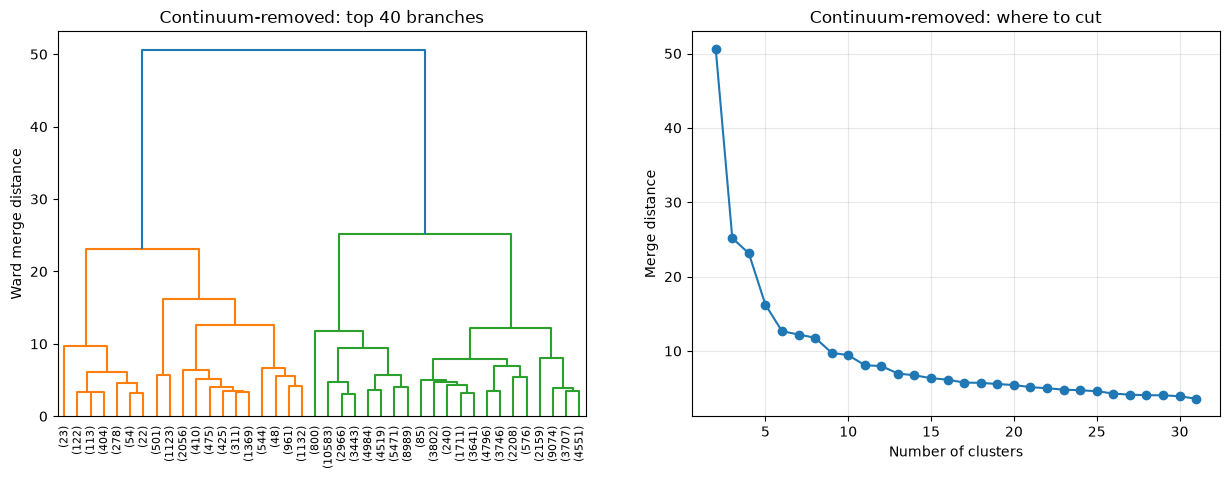

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z_cr, truncate_mode="lastp", p=40, show_leaf_counts=True,
           leaf_rotation=90, ax=ax1)
ax1.set_ylabel("Ward merge distance")
ax1.set_title("Continuum-removed: top 40 branches")

last = Z_cr[-30:, 2][::-1]                                # last 30 merges, largest first
ax2.plot(np.arange(2, 32), last, "o-")
ax2.set_xlabel("Number of clusters"); ax2.set_ylabel("Merge distance")
ax2.set_title("Continuum-removed: where to cut"); ax2.grid(alpha=0.3)
plt.show()

In [42]:
CUT_CR = 9                                             # set from the Cell 17 dendrogram
#N_CLUSTERS_CR = 8                                         # used only while CUT_CR is None

if CUT_CR is not None:
    labels_cr = fcluster(Z_cr, t=CUT_CR, criterion="distance")
else:
    labels_cr = fcluster(Z_cr, t=N_CLUSTERS_CR, criterion="maxclust")

k_cr = int(labels_cr.max())
print("Clusters:", k_cr, " sizes:", np.bincount(labels_cr)[1:])

label_img_cr = np.full(mask.shape, np.nan)
label_img_cr[mask] = labels_cr

Clusters: 10  sizes: [   23   993  1624  5046  2685   800 16992 23963 20805 19491]


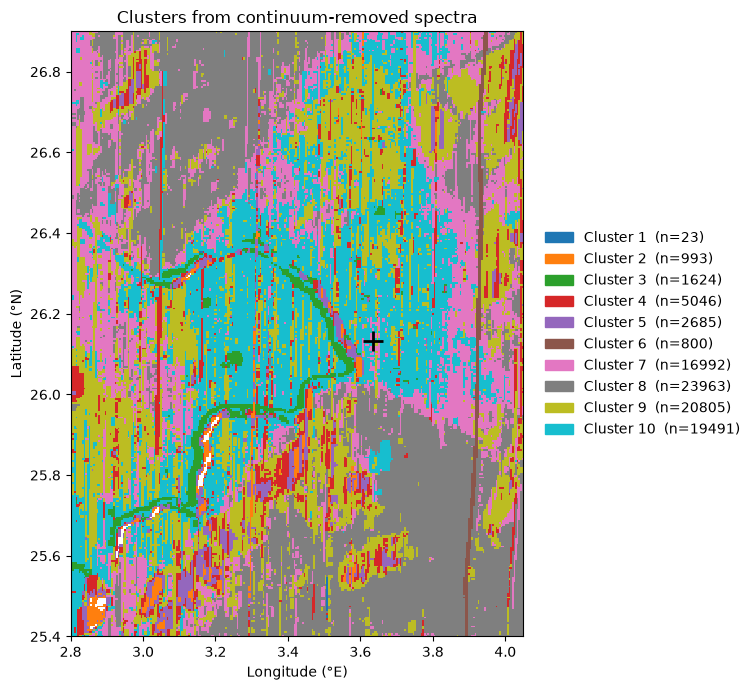

In [44]:
colors_cr = (plt.get_cmap("tab10").colors[:k_cr] if k_cr <= 10
             else plt.get_cmap("tab20").colors[:k_cr])
cmap_cr = ListedColormap(colors_cr)
norm_cr = BoundaryNorm(np.arange(0.5, k_cr + 1.5), k_cr)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(label_img_cr, cmap=cmap_cr, norm=norm_cr, interpolation="nearest",
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.plot(SITE_LON, SITE_LAT, "k+", ms=14, mew=2)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Clusters from continuum-removed spectra")

sizes_cr = np.bincount(labels_cr, minlength=k_cr + 1)[1:]
handles = [Patch(color=colors_cr[i], label=f"Cluster {i + 1}  (n={sizes_cr[i]})")
           for i in range(k_cr)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout(); plt.show()

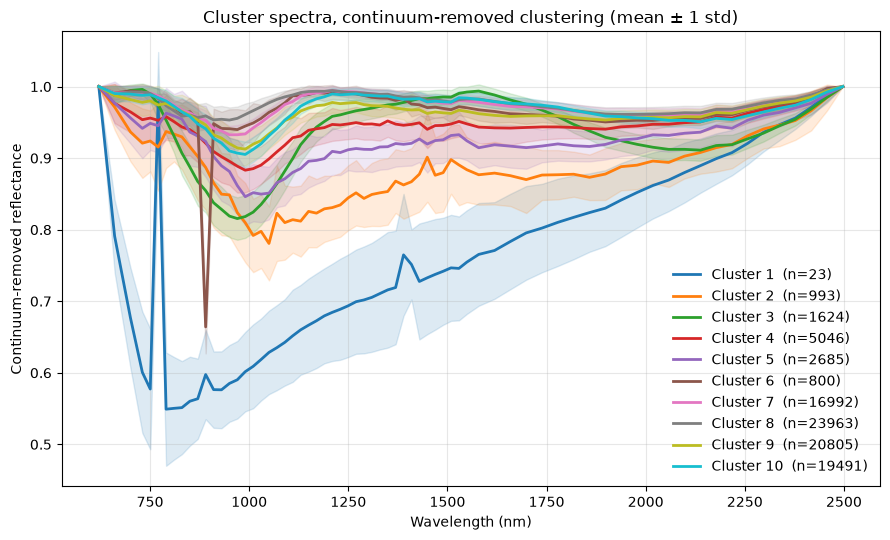

In [45]:
SPEC, YLABEL = X_cr, "Continuum-removed reflectance"   # or: X, "Reflectance"

fig, ax = plt.subplots(figsize=(9, 5.5))
for i in range(k_cr):
    spec = SPEC[labels_cr == i + 1]
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors_cr[i], lw=2,
            label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors_cr[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel(YLABEL)
ax.set_title("Cluster spectra, continuum-removed clustering (mean ± 1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Denoise, destripe, and cluster again